# MenuScan TN · 03.02 Risque de résiliation (T7.2, K19, EF-10)

Autrice : Sarra Abdeljaouad

**Question.** Pour chaque établissement actif, quelle est la probabilité qu'il résilie le mois prochain, et pourquoi ?

**Sortie.** Pour les 265 établissements actifs au 31/12/2026 :
- une probabilité de résiliation en janvier 2027 ;
- un rang ;
- une alerte ;
- les 3 facteurs qui augmentent le plus leur risque.

**Données.** `05_data/features/etablissement_mois.parquet`, préparé par `01_preparation_datasets_ml`.

**Suivi.** Chaque essai est enregistré dans MLflow, en local (`06_exports/journaux`).

## Règles de décision, fixées avant de regarder le test

| Règle | Contenu |
|---|---|
| Choix du modèle | Meilleure AUC sur la **validation** (cibles de juillet à décembre 2025). Le test 2026 n'est pas utilisé pour choisir |
| Modèle utile | Le modèle retenu doit battre d'au moins 0,01 d'AUC la meilleure règle simple (une seule variable), sur la validation |
| Jalon J8 | AUC sur le test 2026 ≥ 0,75. L'intervalle à 95 % est publié avec la valeur |
| Alerte | Les 10 % d'établissements au risque le plus élevé, chaque mois |

In [1]:
import os
import sys
sys.path.insert(0, "../00_commun")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import logging
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
logging.getLogger("mlflow").setLevel(logging.WARNING)

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from menuscan_analytics import config, modeles
from menuscan_analytics.config import BLEU, GRIS, ORANGE
from menuscan_analytics.modeles import CAT, NUM

config.style()
warnings.filterwarnings("ignore", category=UserWarning)
GRAINE = 42

## 1. Données

In [2]:
brut = pd.read_parquet(config.DOSSIER_FEATURES / "etablissement_mois.parquet")
apprentissage = brut.sous_jeu.isin(["ajustement", "validation"])
note_moyenne = brut.loc[apprentissage, "satisfaction_6m"].mean()   # apprise sur l'apprentissage seulement
df = modeles.preparer(brut, note_par_defaut=note_moyenne)

X, y = df[NUM + CAT], df["resilie_mois_suivant"]
aj, va, te, sc = (df.sous_jeu == s for s in ["ajustement", "validation", "test", "a_scorer"])
app = aj | va
pd.DataFrame({"lignes": [aj.sum(), va.sum(), te.sum(), sc.sum()],
              "resiliations": [y[aj].sum(), y[va].sum(), y[te].sum(), np.nan]},
             index=["ajustement", "validation", "test 2026", "à scorer (déc. 2026)"])

,lignes,resiliations
ajustement,927,33.000
validation,781,29.000
test 2026,2458,76.000
à scorer (déc. 2026),265,NaN


**Nouvelle variable : `echeance_annuelle`.** L'EDA avait montré un pic de résiliations vers 11 mois d'ancienneté. J'ai vérifié l'hypothèse de la fin du premier engagement annuel dans les données :
- en facturation annuelle, les 26 résiliations tombent toutes le mois où l'ancienneté atteint 11, 23 ou 35 mois, c'est-à-dire juste avant l'échéance ;
- en dehors de ces mois, il n'y a aucune résiliation annuelle.

La variable vaut 1 ces mois-là.

In [3]:
annuel = df[app & df.periodicite_facturation.eq("annuelle")]
annuel.groupby("echeance_annuelle").resilie_mois_suivant.agg(lignes="count", resiliations="sum", taux="mean")

,lignes,resiliations,taux
echeance_annuelle,,,
0,476,0.000,0.000
1,27,13.000,0.481


## 2. Référence : règles simples (une seule variable)

In [4]:
REGLES = {
    "usage faible (sessions par table et par jour, 3 mois)": -df["sessions_table_jour_3m"],
    "retards de paiement (part sur 6 mois)": df["part_factures_retard_6m"],
    "tickets de support (3 mois)": df["tickets_3m"],
    "échéance annuelle": df["echeance_annuelle"],
}
ref = pd.DataFrame({nom: {"AUC validation": roc_auc_score(y[va], s[va])} for nom, s in REGLES.items()}).T
ref = ref.sort_values("AUC validation", ascending=False)
meilleure_regle, auc_regle_va = ref.index[0], ref.iloc[0, 0]
ref

,AUC validation
retards de paiement (part sur 6 mois),0.676
tickets de support (3 mois),0.658
échéance annuelle,0.615
"usage faible (sessions par table et par jour, 3 mois)",0.581


## 3. Candidats, choix sur la validation

- **Régression logistique**, à 4 niveaux de régularisation (C).
- **Forêt aléatoire**, à 3 tailles minimales de feuille.

Les deux utilisent des classes pondérées : il y a environ 30 lignes sans résiliation pour 1 avec. Chaque candidat est appris sur l'ajustement, mesuré sur la validation, puis enregistré dans MLflow.

In [5]:
def preparateur():
    return ColumnTransformer([("n", StandardScaler(), NUM),
                              ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

def candidat(type_, valeur):
    if type_ == "logistique":
        m = LogisticRegression(C=valeur, class_weight="balanced", max_iter=5000)
    else:
        m = RandomForestClassifier(n_estimators=500, min_samples_leaf=valeur, class_weight="balanced_subsample",
                                   random_state=GRAINE, n_jobs=-1)
    return Pipeline([("pre", preparateur()), ("modele", m)])

GRILLE = [("logistique", c) for c in (0.03, 0.1, 0.3, 1.0)] + [("foret", f) for f in (10, 20, 50)]

config.experience_mlflow("MenuScan_resiliation")
lignes = []
for type_, valeur in GRILLE:
    m = candidat(type_, valeur).fit(X[aj], y[aj])
    p = m.predict_proba(X[va])[:, 1]
    res = {"type": type_, "parametre": "C" if type_ == "logistique" else "min_samples_leaf", "valeur": valeur,
           "auc_validation": roc_auc_score(y[va], p), "ap_validation": average_precision_score(y[va], p)}
    with mlflow.start_run(run_name=f"{type_}_{valeur}"):
        mlflow.set_tag("etape", "choix_sur_validation")
        mlflow.log_params({"type": type_, res["parametre"]: valeur, "variables": len(NUM) + len(CAT)})
        mlflow.log_metrics({"auc_validation": res["auc_validation"], "ap_validation": res["ap_validation"]})
    lignes.append(res)
candidats = pd.DataFrame(lignes).sort_values("auc_validation", ascending=False).reset_index(drop=True)
config.enregistrer_table(candidats, "ML02_candidats_validation", index=False)
candidats

2026/11/28 14:38:10 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/28 14:38:10 INFO mlflow.store.db.utils: Updating database tables


,type,parametre,valeur,auc_validation,ap_validation
0,logistique,C,0.030,0.862,0.317
1,logistique,C,0.100,0.849,0.322
2,logistique,C,0.300,0.840,0.323
3,logistique,C,1.000,0.837,0.323
4,foret,min_samples_leaf,50.000,0.791,0.130
5,foret,min_samples_leaf,20.000,0.790,0.121
6,foret,min_samples_leaf,10.000,0.785,0.121


In [6]:
choix = candidats.iloc[0]
gain = choix.auc_validation - auc_regle_va
print(f"Retenu : {choix.type} ({choix.parametre} = {choix.valeur}), AUC validation {choix.auc_validation:.3f}")
print(f"Meilleure règle simple : {meilleure_regle}, AUC validation {auc_regle_va:.3f} ; gain {gain:+.3f}")
assert gain >= 0.01, "le modèle ne bat pas la règle simple d'au moins 0,01 : ne pas le retenir"
print("Règle « modèle utile » respectée.")

Retenu : logistique (C = 0.03), AUC validation 0.862
Meilleure règle simple : retards de paiement (part sur 6 mois), AUC validation 0.676 ; gain +0.186
Règle « modèle utile » respectée.


## 4. Mesure finale sur 2026 (une seule fois)

Le candidat retenu est réappris sur tout l'apprentissage (ajustement + validation), puis mesuré sur le test 2026.

L'intervalle à 95 % vient d'un bootstrap **par établissement** : on tire des établissements, pas des lignes. Les mois d'un même établissement se ressemblent, et un tirage par ligne donnerait un intervalle trop étroit.

In [7]:
modele = candidat(choix.type, choix.valeur).fit(X[app], y[app])
p_test = modele.predict_proba(X[te])[:, 1]
auc, bas, haut = modeles.auc_bootstrap(y[te], p_test, df.loc[te, "etablissement_id"])
auc_regle_te = roc_auc_score(y[te], REGLES[meilleure_regle][te])
ap = average_precision_score(y[te], p_test)

# Alerte : les 10 % les plus à risque de chaque mois
t = df.loc[te, ["mois", "etablissement_id"]].assign(y=y[te].values, p=p_test)
t["rang_mois"] = t.groupby("mois")["p"].rank(ascending=False, method="first")
t["alerte"] = t["rang_mois"] <= np.ceil(0.10 * t.groupby("mois")["p"].transform("size"))
precision_alerte = t.loc[t.alerte, "y"].mean()
rappel_alerte = t.loc[t.y == 1, "alerte"].mean()

resultat = pd.Series({
    "AUC test 2026": auc, "AUC borne basse 95 %": bas, "AUC borne haute 95 %": haut,
    f"AUC règle simple ({meilleure_regle})": auc_regle_te,
    "Précision moyenne (AP)": ap, "Taux de résiliation de base": y[te].mean(),
    "Alerte 10 % : précision": precision_alerte, "Alerte 10 % : rappel": rappel_alerte,
})
config.enregistrer_table(resultat.to_frame("valeur"), "ML02_mesures_test_2026")
resultat.to_frame("valeur")

,valeur
AUC test 2026,0.794
AUC borne basse 95 %,0.738
AUC borne haute 95 %,0.850
AUC règle simple (retards de paiement (part sur 6 mois)),0.668
Précision moyenne (AP),0.186
Taux de résiliation de base,0.031
Alerte 10 % : précision,0.147
Alerte 10 % : rappel,0.487


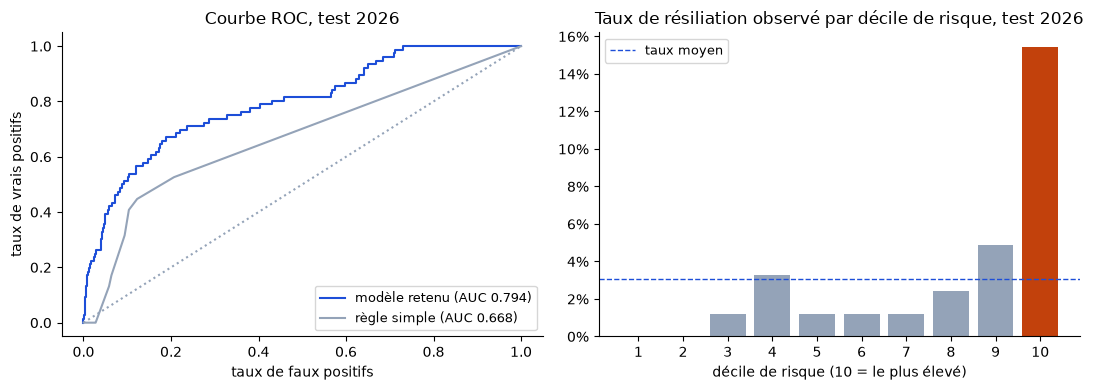

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fpr, tpr, _ = roc_curve(y[te], p_test)
axes[0].plot(fpr, tpr, color=BLEU, label=f"modèle retenu (AUC {auc:.3f})")
fpr2, tpr2, _ = roc_curve(y[te], REGLES[meilleure_regle][te])
axes[0].plot(fpr2, tpr2, color=GRIS, label=f"règle simple (AUC {auc_regle_te:.3f})")
axes[0].plot([0, 1], [0, 1], ":", color=GRIS)
axes[0].set_xlabel("taux de faux positifs"); axes[0].set_ylabel("taux de vrais positifs")
axes[0].set_title("Courbe ROC, test 2026"); axes[0].legend(loc="lower right", fontsize=9)
d = pd.DataFrame({"y": y[te].values, "p": p_test})
d["decile"] = pd.qcut(d.p.rank(method="first"), 10, labels=range(1, 11))
taux = d.groupby("decile", observed=True).y.mean()
axes[1].bar(taux.index.astype(str), taux.values, color=[GRIS] * 9 + [ORANGE])
axes[1].axhline(d.y.mean(), color=BLEU, ls="--", lw=1, label="taux moyen")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_title("Taux de résiliation observé par décile de risque, test 2026")
axes[1].set_xlabel("décile de risque (10 = le plus élevé)"); axes[1].legend(fontsize=9)
plt.tight_layout(); config.enregistrer_figure(fig, "ML02_roc_deciles_test_2026"); plt.show()

In [9]:
statut_j8 = "ATTEINT" if auc >= 0.75 else "NON ATTEINT"
print(f"Jalon J8 (AUC ≥ 0,75 sur 2026) : {statut_j8}. AUC {auc:.3f}, intervalle à 95 % [{bas:.3f} ; {haut:.3f}]")
if bas < 0.75 <= auc:
    print("Attention : la borne basse est sous 0,75. Le seuil est atteint en valeur centrale, pas avec certitude.")

Jalon J8 (AUC ≥ 0,75 sur 2026) : ATTEINT. AUC 0.794, intervalle à 95 % [0.738 ; 0.850]
Attention : la borne basse est sous 0,75. Le seuil est atteint en valeur centrale, pas avec certitude.


## 5. Probabilités : correction de la pondération

La pondération des classes aide le modèle à repérer les cas rares. En contrepartie, elle gonfle les probabilités : en moyenne, le modèle prédit beaucoup plus de résiliations qu'il n'y en a. Ce biais ne change pas le classement des établissements, donc il ne touche pas l'AUC.

Pour publier une probabilité lisible, on corrige la cote du rapport de pondération : cote corrigée = cote du modèle × (positifs / négatifs de l'apprentissage). On vérifie ensuite sur le test que la moyenne prédite colle au taux observé.

In [10]:
rapport = y[app].sum() / (len(y[app]) - y[app].sum())

def probabilite(m, X_):
    p = m.predict_proba(X_)[:, 1]
    cote = p / (1 - p) * rapport
    return cote / (1 + cote)

p_test_corr = probabilite(modele, X[te])
calibrage = pd.DataFrame({"y": y[te].values, "p": p_test_corr})
calibrage["groupe"] = pd.qcut(calibrage.p.rank(method="first"), 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
cal = calibrage.groupby("groupe", observed=True).agg(probabilite_moyenne=("p", "mean"), taux_observe=("y", "mean"),
                                                     lignes=("y", "size"))
print(f"Moyenne prédite sur 2026 : {p_test_corr.mean():.2%} ; taux observé : {y[te].mean():.2%} "
      f"(sans correction : {p_test.mean():.2%})")
config.enregistrer_table(cal, "ML02_calibrage_test_2026")
cal

Moyenne prédite sur 2026 : 3.77% ; taux observé : 3.09% (sans correction : 33.91%)


,probabilite_moyenne,taux_observe,lignes
groupe,,,
Q1,0.002,0.000,492
Q2,0.008,0.022,491
Q3,0.015,0.012,492
Q4,0.028,0.018,491
Q5,0.135,0.102,492


## 6. Facteurs du risque

### 6.1 Lecture globale

Les coefficients de la régression logistique portent sur des variables centrées-réduites. Un coefficient positif augmente le risque.

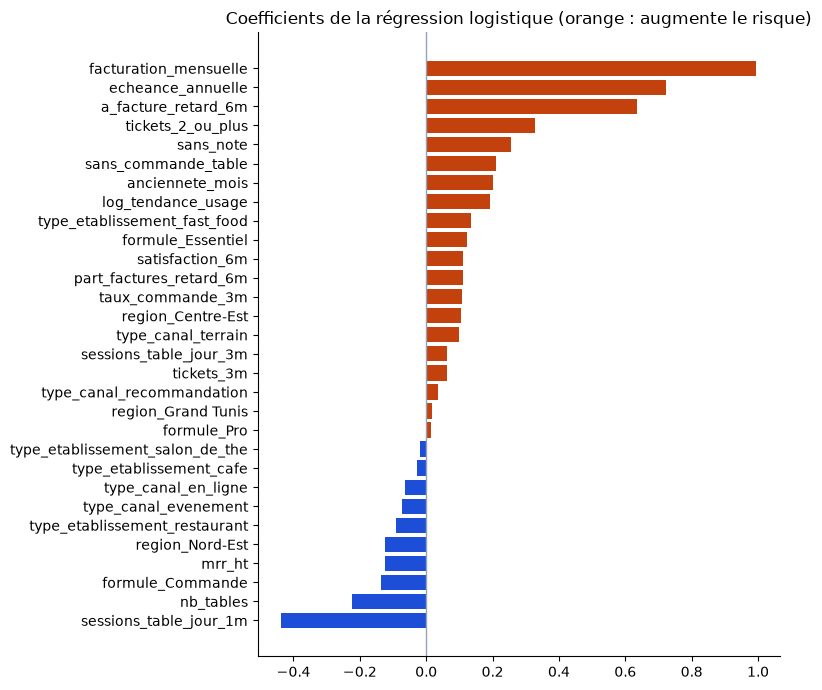

In [11]:
explicatif = modele if choix.type == "logistique" else candidat("logistique", 0.3).fit(X[app], y[app])
noms = explicatif[0].get_feature_names_out()
coef = pd.Series(explicatif[-1].coef_[0], index=[n.split("__", 1)[1] for n in noms]).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(coef.index, coef.values, color=[ORANGE if v > 0 else BLEU for v in coef.values])
ax.axvline(0, color=GRIS, lw=1)
ax.set_title("Coefficients de la régression logistique (orange : augmente le risque)")
plt.tight_layout(); config.enregistrer_figure(fig, "ML02_coefficients"); plt.show()
_ = config.enregistrer_table(coef.to_frame("coefficient"), "ML02_coefficients")

**Précaution de lecture.** Un coefficient mesure l'effet d'une variable **à valeurs égales des autres**. Les variables d'usage sur 1 mois et sur 3 mois sont très liées entre elles. Leurs coefficients se partagent l'effet et ne se lisent pas séparément : c'est pourquoi les facteurs publiés les regroupent.

**Trois signes à ne pas surinterpréter.**
- **Satisfaction support.** Le coefficient de la note est positif, alors que l'EDA montre une note un peu plus basse avant une résiliation. La note n'existe que si l'établissement a ouvert des tickets : elle est liée aux variables de tickets, qui portent déjà l'effet. Le facteur « Satisfaction support » signale donc un profil de support atypique, pas « les clients satisfaits partent ».
- **Ancienneté.** Le coefficient est positif à valeurs égales des autres variables. Il ne contredit pas l'EDA (résiliations plutôt jeunes) : l'effet « jeune » passe par l'échéance annuelle et la facturation mensuelle.
- **Régularisation forte (C = 0,03).** Elle réduit les coefficients vers 0 pour limiter le surapprentissage avec peu de résiliations. Les valeurs servent à comparer les variables entre elles, pas à chiffrer un effet.

### 6.2 Les 3 facteurs par établissement

Pour un établissement, la contribution d'un facteur est l'écart qu'il crée par rapport à un établissement moyen. On la calcule sur la cote de résiliation, en logarithme. On publie les 3 facteurs dont la contribution positive est la plus forte.

Un établissement peut avoir moins de 3 facteurs. Cela arrive s'il est moins risqué que la moyenne sur la plupart des points.

## 7. Scores au 31/12/2026 (risque de résiliation en janvier 2027)

In [12]:
a_scorer = df[sc].copy()
a_scorer["probabilite"] = probabilite(modele, X[sc])
a_scorer["rang"] = a_scorer["probabilite"].rank(ascending=False, method="first").astype(int)
a_scorer["alerte"] = a_scorer["rang"] <= int(np.ceil(0.10 * len(a_scorer)))
contrib = modeles.contributions_logistique(explicatif, X[sc], X[app])
a_scorer = a_scorer.join(modeles.trois_facteurs(contrib))
scores = a_scorer[["etablissement_id", "mois", "probabilite", "rang", "alerte",
                   "facteur_1", "facteur_2", "facteur_3", "formule", "anciennete_mois"]].sort_values("rang")
scores["mois"] = "2026-12-01"
print(f"{len(scores)} établissements scorés ; {scores.alerte.sum()} en alerte ; "
      f"résiliations attendues en janvier 2027 : {scores.probabilite.sum():.1f}")
scores.head(15)

265 établissements scorés ; 27 en alerte ; résiliations attendues en janvier 2027 : 9.9


,etablissement_id,mois,probabilite,rang,alerte,facteur_1,facteur_2,facteur_3,formule,anciennete_mois
2190,ETB0002,2026-12-01,0.705,1,True,Échéance de l'engagement annuel,Ancienneté,Satisfaction support,Essentiel,35
3961,ETB0235,2026-12-01,0.416,2,True,Échéance de l'engagement annuel,Ancienneté,Taille (tables),Essentiel,11
4268,ETB0317,2026-12-01,0.383,3,True,Retards de paiement,Tickets de support,Facturation mensuelle,Essentiel,5
3889,ETB0220,2026-12-01,0.383,4,True,Échéance de l'engagement annuel,Satisfaction support,Ancienneté,Commande,11
1731,ETB0228,2026-12-01,0.364,5,True,Échéance de l'engagement annuel,Satisfaction support,Ancienneté,Pro,11
3909,ETB0223,2026-12-01,0.312,6,True,Échéance de l'engagement annuel,Ancienneté,Montant de l'abonnement,Essentiel,11
1012,ETB0117,2026-12-01,0.217,7,True,Retards de paiement,Tickets de support,Facturation mensuelle,Pro,20
4337,ETB0340,2026-12-01,0.193,8,True,Retards de paiement,Tickets de support,Facturation mensuelle,Commande,3
1604,ETB0207,2026-12-01,0.156,9,True,Retards de paiement,Facturation mensuelle,Ancienneté,Essentiel,13
3770,ETB0201,2026-12-01,0.152,10,True,Retards de paiement,Facturation mensuelle,Ancienneté,Essentiel,13


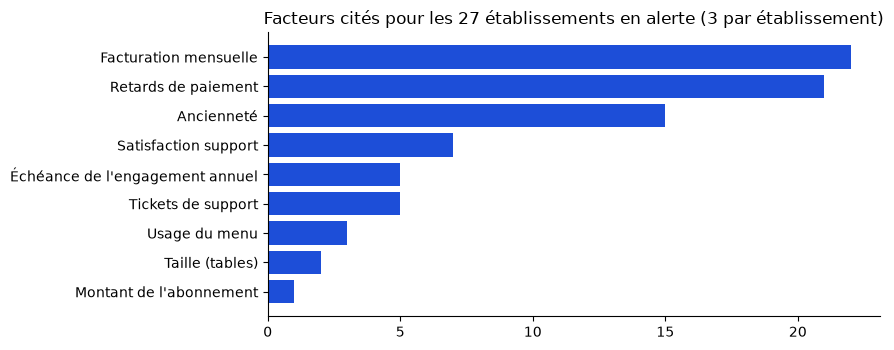

In [13]:
fig, ax = plt.subplots()
f = pd.concat([scores.loc[scores.alerte, c] for c in ["facteur_1", "facteur_2", "facteur_3"]]).value_counts()
ax.barh(f.index[::-1], f.values[::-1], color=BLEU)
ax.set_title(f"Facteurs cités pour les {scores.alerte.sum()} établissements en alerte (3 par établissement)")
plt.tight_layout(); config.enregistrer_figure(fig, "ML02_facteurs_alertes"); plt.show()

**Lecture.** La liste en alerte est un ordre de priorité pour l'équipe Succès client, pas une prédiction certaine.

Sur le test 2026, la précision de l'alerte mesure la part de vraies résiliations parmi les établissements signalés. Les autres établissements signalés restent fragiles, et c'est souvent sur eux qu'un contact a le plus de chances d'éviter la résiliation.

## 8. Enregistrement : modèle, prédictions, fiche, MLflow

In [14]:
config.DOSSIER_MODELES.mkdir(parents=True, exist_ok=True)
config.DOSSIER_PREDICTIONS.mkdir(parents=True, exist_ok=True)
chemin_modele = config.DOSSIER_MODELES / "resiliation.joblib"
joblib.dump({"modele": modele, "explicatif": explicatif, "rapport_ponderation": rapport,
             "note_par_defaut": note_moyenne, "variables": NUM + CAT}, chemin_modele)

pred_test = df.loc[te, ["etablissement_id", "mois", "resilie_mois_suivant"]].assign(probabilite=p_test_corr)
pred_test.to_parquet(config.DOSSIER_PREDICTIONS / "resiliation_test_2026.parquet", index=False)
scores.to_parquet(config.DOSSIER_PREDICTIONS / "resiliation_scores_2026_12.parquet", index=False)
config.enregistrer_table(scores, "ML02_scores_2026_12", index=False)

fiche = {
    "objet": "probabilité de résiliation le mois suivant, par établissement actif (K19, EF-10)",
    "donnees": "05_data/features/etablissement_mois.parquet",
    "apprentissage": "mois de janvier 2024 à novembre 2025 (cibles 2024-2025)",
    "validation": "mois de juin à novembre 2025 (choix du modèle)",
    "test": "mois de décembre 2025 à novembre 2026 (cibles 2026)",
    "algorithme": f"{choix.type}, {choix.parametre} = {choix.valeur}, classes pondérées",
    "variables": NUM + CAT,
    "auc_validation": round(float(choix.auc_validation), 4),
    "auc_test_2026": round(float(auc), 4), "auc_test_ic95": [round(bas, 4), round(haut, 4)],
    "auc_regle_simple_test": round(float(auc_regle_te), 4), "regle_simple": meilleure_regle,
    "alerte": "10 % des établissements les plus à risque", "precision_alerte_test": round(float(precision_alerte), 4),
    "rappel_alerte_test": round(float(rappel_alerte), 4),
    "jalon_J8": statut_j8,
    "limites": ["données synthétiques : le modèle retrouve les règles du générateur",
                "76 résiliations en test : intervalle de l'AUC large",
                "periodicite_facturation = valeur actuelle de l'établissement"],
}
modeles.enregistrer_fiche("resiliation", fiche)

with mlflow.start_run(run_name="retenu_test_2026"):
    mlflow.set_tag("etape", "mesure_finale_test_2026")
    mlflow.log_params({"type": choix.type, choix.parametre: choix.valeur, "variables": len(NUM) + len(CAT)})
    mlflow.log_metrics({"auc_validation": choix.auc_validation, "auc_test": auc, "auc_test_bas": bas,
                        "auc_test_haut": haut, "ap_test": ap, "precision_alerte": precision_alerte,
                        "rappel_alerte": rappel_alerte})
    mlflow.log_artifact(str(chemin_modele))
    mlflow.log_artifact(str(config.DOSSIER_MODELES / "fiches" / "resiliation.json"))
print("Enregistré :", chemin_modele.name, "· fiches/resiliation.json · prédictions · run MLflow")

Enregistré : resiliation.joblib · fiches/resiliation.json · prédictions · run MLflow


## 9. Conclusion

Les chiffres sont dans les sections 4 et 5, et dans la fiche `06_exports/modeles/fiches/resiliation.json`.

- **Méthode.** Choix sur la validation 2025, mesure unique sur 2026, intervalle par établissement, comparaison à une règle simple.
- **Limite principale.** Les données sont synthétiques. Le modèle retrouve les règles du générateur, ce qui valide la chaîne de bout en bout, pas sa performance sur de vrais clients.
- **Suite (T7.4).** Publication des scores dans le schéma `ml`, page K19 dans Power BI, décision J8 avec le sponsor.

Pour consulter les essais : depuis `08_analyse_ml`, lancer `mlflow ui --backend-store-uri sqlite:///06_exports/journaux/mlflow.db`, puis ouvrir http://127.0.0.1:5000.